# 07 — Robustness Checks
**Stage:** Evaluation

**TL;DR:** Three tests hold (faster trend, placebo years, flagged days), but the **2016 test changes the answer**. 2016 had the same dry monsoon (250 mm) and **no free electricity**, and its demand followed **almost exactly the same path above the rain model as 2023** during Aug–Dec (+16.7% vs +21.5% in Aug–Oct). So the 2023 surge was **mostly the failed monsoon (best estimate ~3/4, plausible range 24–78%)**; **free electricity ≤13%**. The two years only diverge **afterwards**: 2017 returned to normal, while from early 2024 demand stayed high. That lasting rise is a **separate phenomenon** neither cause fully explains.

## 1. Question
Can we **break** the findings of Notebooks 05–06? (Riley: "be both skeptic and champion"; Card & Krueger: placebo
tests and a second natural experiment.)

Findings under test (Aug–Oct 2023, excess ≈ 1,860 MW over the calendar + heat + trend model):
- failed monsoon ≈ 445–664 MW (24–36%), free electricity ≤ 238 MW (≤ 13%), "other" lasting ≈ 958–1,414 MW.

| # | Test | The finding would break if… |
|---|---|---|
| 1 | Faster growth trend (4–8%/yr instead of 2.96%) | the "other" part disappears with a plausible trend |
| 2 | Placebo start dates (1 Aug 2021, 2022; 2015) | the method finds a large "effect" in years with no event |
| 3 | Drop the 8 flagged days (Notebook 02) | the numbers change noticeably |
| 4 | **2016**: equally dry, **no** free electricity | a drought alone produces the same pattern → our drought share is too low |

## 2. Expectation *(written before running)*
1. A faster trend will shrink the "other" part somewhat, but the trend only acts for ~0.7 years after training ends,
   so it should not remove a ~1,400 MW step.
2. Placebo years should show gaps within the model's normal error (±4% monthly, ~±8% for 2 std).
3. Dropping the flagged days should change almost nothing (they are in Oct–Nov, the 2023 gap is in Aug–Oct).
4. **2016 is the real test.** If 2016 shows a large excess beyond what the rain model explains, then our models
   underestimate full-season drought effects, and some of 2023's "other" is really drought.

## 3. Data used
Same features and models as Notebook 05 (`src/features.py`, `src/model.py`). For 2015–2017 the models are trained
on **2011 → year−1** (2011–2012 are the least reliable years, see Notebook 02). The 30-day rain anomaly regression is
the same as Notebook 06.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from src import config, plots, features as F, model as M

plots.setup()
pd.set_option("display.width", 200)
P = config.DATA_PROCESSED
df = F.build_hourly_frame(pd.read_parquet(P / "load_hourly.parquet"), pd.read_parquet(P / "weather_daily.parquet"),
                          pd.read_parquet(P / "weather_hourly_blr.parquet"), pd.read_parquet(P / "holidays.parquet"))
FEAT_A = F.CALENDAR_FEATURES + F.TEMP_FEATURES
FEAT_B = FEAT_A + F.RAIN_FEATURES


def fit_pair(train_start, train_end, growth=None):
    mA = M.CounterfactualModel(FEAT_A, fixed_growth=growth).fit(df, train_start, train_end)
    mB = M.CounterfactualModel(FEAT_B, fixed_growth=growth).fit(df, train_start, train_end)
    return mA, mB


def evaluate(mA, mB, yr, drop_days=None):
    """Aug–Oct decomposition for one year (same definitions as Notebooks 05–06)."""
    p = df.loc[f"{yr}-08-01":f"{yr}-12-31"].dropna(subset=["load_mw"] + FEAT_B).copy()
    if drop_days is not None:
        p = p[~p.index.normalize().isin(drop_days)]
    p["A"], p["B"] = mA.predict(p).values, mB.predict(p).values
    w = p.loc[f"{yr}-08-01":f"{yr}-10-31"]
    base = w.A.mean()
    dd = p[["load_mw", "A", "rain_30d_anom"]].resample("D").mean().dropna()
    dd["gap_A_%"] = (dd.load_mw / dd.A - 1) * 100
    r = sm.OLS(dd["gap_A_%"], sm.add_constant(dd.rain_30d_anom / 100)).fit()
    anom_aug_oct = dd.loc[f"{yr}-08-01":f"{yr}-10-31"].rain_30d_anom.mean()
    return {"year": yr, "trend %/yr": mA.trend.growth_per_year * 100, "expected MW": base,
            "total excess MW": w.load_mw.mean() - base, "total excess %": (w.load_mw.mean() / base - 1) * 100,
            "rain effect, Model B (MW)": w.B.mean() - base,
            "rain effect, regression (MW)": r.params.iloc[1] * anom_aug_oct / 100 / 100 * base,
            "unexplained vs B (MW)": w.load_mw.mean() - w.B.mean(),
            "unexplained vs B %": (w.load_mw.mean() / w.B.mean() - 1) * 100}


base_A, base_B = fit_pair("2015-01-01", "2022-12-31 23:00")
main = evaluate(base_A, base_B, 2023)
pd.Series(main).round(1).to_frame("2023 main result")

,2023 main result
year,2023.0
trend %/yr,3.0
expected MW,8640.0
total excess MW,1859.5
total excess %,21.5
"rain effect, Model B (MW)",445.1
"rain effect, regression (MW)",513.5
unexplained vs B (MW),1414.4
unexplained vs B %,15.6


## 4. Analysis
### Test 1 — Faster growth trend
*Why:* if demand was simply growing faster after 2022 than the 2011–2022 trend (2.96%/yr), the "other" part could be
ordinary growth. Re-run everything with the trend forced to 4%, 5%, 6% and 8% per year.

In [2]:
rows = [dict(main, **{"assumed growth": "fitted (2.96%)"})]
for g in [0.04, 0.05, 0.06, 0.08]:
    mA, mB = fit_pair("2015-01-01", "2022-12-31 23:00", growth=g)
    rows.append(dict(evaluate(mA, mB, 2023), **{"assumed growth": f"{g:.0%}"}))
t1 = pd.DataFrame(rows).set_index("assumed growth")[["total excess MW", "rain effect, Model B (MW)",
                                                     "rain effect, regression (MW)", "unexplained vs B (MW)", "unexplained vs B %"]]
t1.round(0)

,total excess MW,"rain effect, Model B (MW)","rain effect, regression (MW)",unexplained vs B (MW),unexplained vs B %
assumed growth,,,,,
fitted (2.96%),1860.0,445.0,513.0,1414.0,16.0
4%,1745.0,468.0,498.0,1276.0,14.0
5%,1620.0,400.0,500.0,1220.0,13.0
6%,1586.0,435.0,521.0,1151.0,12.0
8%,1501.0,685.0,545.0,816.0,8.0


_What I see:_ even with the trend **doubled to 6%/yr**, ~1,150 MW stays unexplained. Faster growth can only explain
a few hundred MW, because the trend acts for less than a year after training ends.

### Test 2 — Placebo start dates
*Why:* run the identical method on years when **nothing happened** (no scheme). If it finds a big gap there too,
the method — not the event — is creating the effect.

In [3]:
plac = []
for yr, start in [(2015, "2011-01-01"), (2021, "2015-01-01"), (2022, "2015-01-01")]:
    mA, mB = fit_pair(start, f"{yr - 1}-12-31 23:00")
    plac.append(evaluate(mA, mB, yr))
plac.append(main)
t2 = pd.DataFrame(plac).set_index("year")[["total excess %", "unexplained vs B %", "unexplained vs B (MW)"]]
t2.round(1)

,total excess %,unexplained vs B %,unexplained vs B (MW)
year,,,
2015,-1.6,-3.4,-221.8
2021,10.0,4.4,322.4
2022,-4.7,-4.5,-342.1
2023,21.5,15.6,1414.4


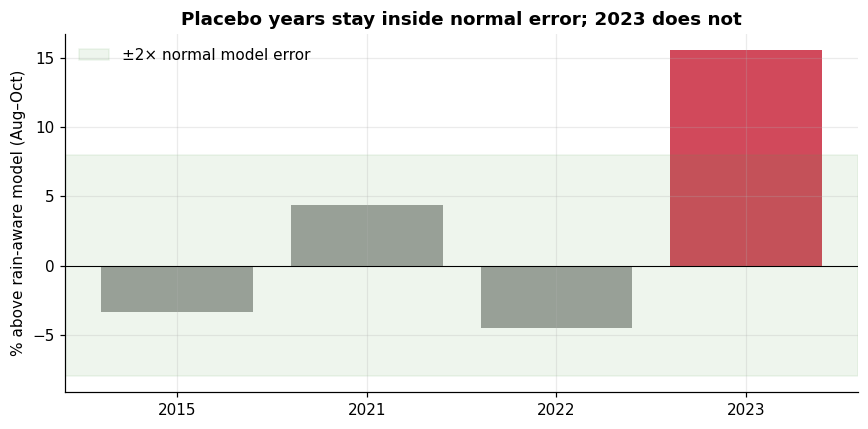

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [plots.COLORS["muted"]] * 3 + [plots.COLORS["highlight"]]
ax.bar(t2.index.astype(str), t2["unexplained vs B %"], color=colors)
ax.axhspan(-8, 8, color="#59a14f", alpha=0.1, label="±2× normal model error")
ax.axhline(0, color="black", lw=0.7)
ax.set_ylabel("% above rain-aware model (Aug–Oct)")
ax.set_title("Placebo years stay inside normal error; 2023 does not")
ax.legend(); plt.tight_layout(); plots.save(fig, "07_placebo"); plt.show()

### Test 3 — Drop the flagged days
*Why:* Notebook 02 flagged 8 days in Oct–Nov 2023 where hourly data and the daily total disagree by >3%.

In [5]:
flags = pd.read_parquet(P / "daily_crosscheck.parquet")
bad = flags.index[flags.xcheck_flag]
t3 = pd.DataFrame([main, evaluate(base_A, base_B, 2023, drop_days=bad)], index=["all days", "flagged days removed"])
t3[["total excess MW", "rain effect, Model B (MW)", "unexplained vs B (MW)"]].round(0)

,total excess MW,"rain effect, Model B (MW)",unexplained vs B (MW)
all days,1860.0,445.0,1414.0
flagged days removed,1866.0,453.0,1414.0


### Test 4 — 2016: a drought year without free electricity
*Why:* Aug–Oct 2016 farm-belt rain was **250 mm** (2023: 256 mm) and there was **no Gruha Jyothi**. If the method
finds a similar "unexplained" excess in 2016, that excess must be drought (or something else), not the scheme.
2017 had normal rain, so it shows whether the 2016 excess persisted.

In [6]:
mA16, mB16 = fit_pair("2011-01-01", "2015-12-31 23:00")
t4 = pd.DataFrame([evaluate(mA16, mB16, 2016), evaluate(mA16, mB16, 2017), main, evaluate(base_A, base_B, 2024)]).set_index("year")
t4.insert(0, "situation", ["drought, no scheme", "normal rain, no scheme", "drought + scheme", "normal rain + scheme"])
t4[["situation", "total excess %", "total excess MW", "rain effect, Model B (MW)", "unexplained vs B %", "unexplained vs B (MW)"]].round(1)

,situation,total excess %,total excess MW,"rain effect, Model B (MW)",unexplained vs B %,unexplained vs B (MW)
year,,,,,,
2016,"drought, no scheme",16.7,1080.0,162.8,13.8,917.2
2017,"normal rain, no scheme",-2.4,-161.2,10.4,-2.6,-171.6
2023,drought + scheme,21.5,1859.5,445.1,15.6,1414.4
2024,normal rain + scheme,12.3,1003.0,-330.2,17.1,1333.2


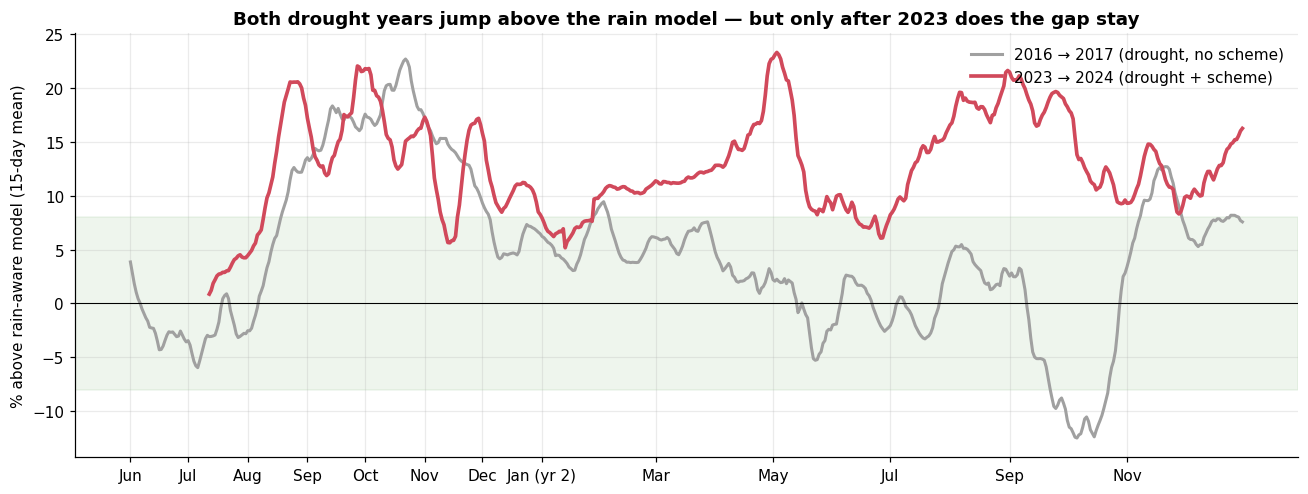

In [7]:
def gap_series(mB, start, end):
    p = df.loc[start:end].dropna(subset=["load_mw"] + FEAT_B)
    s = (p.load_mw / mB.predict(p).values - 1) * 100
    return s.resample("D").mean().rolling(15, center=True, min_periods=7).mean()

g16 = gap_series(mB16, "2016-06-01", "2017-12-31")
g23 = gap_series(base_B, "2023-07-13", "2024-12-31")
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot((g16.index - pd.Timestamp("2016-01-01")).days, g16.values, color=plots.COLORS["muted"], lw=2, label="2016 → 2017 (drought, no scheme)")
ax.plot((g23.index - pd.Timestamp("2023-01-01")).days, g23.values, color=plots.COLORS["highlight"], lw=2.4, label="2023 → 2024 (drought + scheme)")
ax.axhspan(-8, 8, color="#59a14f", alpha=0.1)
ax.axhline(0, color="black", lw=0.7)
ticks = [pd.Timestamp(f"2016-{m:02d}-01") for m in range(6, 13)] + [pd.Timestamp(f"2017-{m:02d}-01") for m in range(1, 13, 2)]
ax.set_xticks([(t - pd.Timestamp("2016-01-01")).days for t in ticks],
              [t.strftime("%b") + (" (yr 2)" if t.year == 2017 and t.month == 1 else "") for t in ticks])
ax.set_ylabel("% above rain-aware model (15-day mean)")
ax.set_title("Both drought years jump above the rain model — but only after 2023 does the gap stay")
ax.legend(loc="upper right"); plt.tight_layout(); plots.save(fig, "07_2016_vs_2023"); plt.show()

_What I see:_ the 2016 drought (no scheme) also rose far above the rain-aware model — so **the models underestimate
what a full-season drought does**. After 2016 the gap **fell back to normal** in 2017; after 2023 it **stayed high**
through 2024.

### Step 4.5 — Revised split
Two ways to estimate the failed-monsoon share of the Aug–Oct 2023 excess:
- **Model-based (Notebooks 05–06):** 445–664 MW — likely too low (Test 4).
- **2016 analogue:** if the 2023 drought raised demand as much as the 2016 drought did (in % terms), the drought
  part is `2016 excess % / 2023 excess %` of the total. 2023's drought was at least as severe (reservoir 42% vs 56%),
  so this is a reasonable upper-range estimate.

Free electricity stays bounded by official household data (≤ 238 MW, Notebook 06).

In [8]:
total = main["total excess MW"]
ex16 = t4.loc[2016, "total excess %"]
drought_lo = min(main["rain effect, Model B (MW)"], main["rain effect, regression (MW)"])
drought_hi = ex16 / main["total excess %"] * total
hh_hi = 238
rev = pd.DataFrame({
    "low MW": [drought_lo, 0, max(total - drought_hi - hh_hi, 0)],
    "high MW": [drought_hi, hh_hi, total - drought_lo],
}, index=["Failed monsoon", "Free electricity (upper bound)", "Other"])
rev["low %"] = rev["low MW"] / total * 100
rev["high %"] = rev["high MW"] / total * 100
print(f"Total excess Aug–Oct 2023: {total:,.0f} MW  |  2016 excess: {ex16:.1f}%  vs 2023: {main['total excess %']:.1f}%")
rev.round(0)

Total excess Aug–Oct 2023: 1,860 MW  |  2016 excess: 16.7%  vs 2023: 21.5%


,low MW,high MW,low %,high %
Failed monsoon,445.0,1444.0,24.0,78.0
Free electricity (upper bound),0.0,238.0,0.0,13.0
Other,177.0,1414.0,10.0,76.0


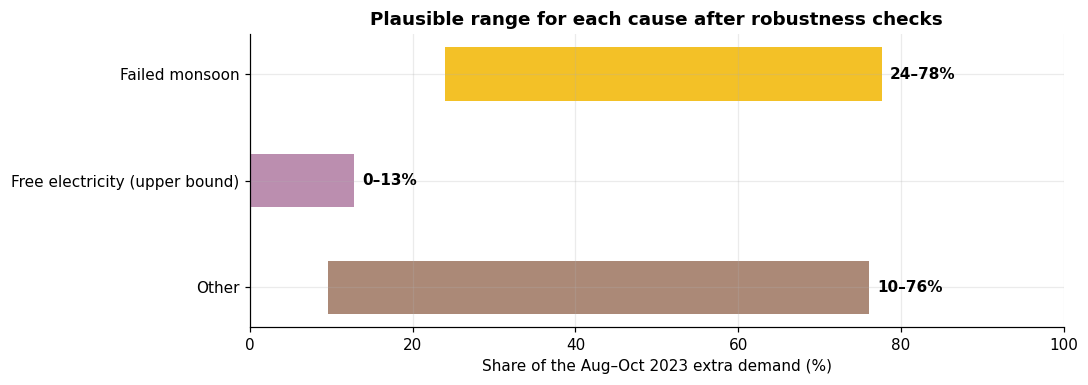

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (name, r) in enumerate(rev.iterrows()):
    c = [plots.COLORS["solar"], "#b07aa1", plots.COLORS["central_import"]][i]
    ax.barh(i, r["high %"] - r["low %"], left=r["low %"], color=c, alpha=0.85, height=0.5)
    ax.text(r["high %"] + 1, i, f"{r['low %']:.0f}–{r['high %']:.0f}%", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(range(3), rev.index); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel("Share of the Aug–Oct 2023 extra demand (%)")
ax.set_title("Plausible range for each cause after robustness checks")
plt.tight_layout(); plots.save(fig, "07_revised_ranges"); plt.show()

### Step 4.6 — Scorecard

In [10]:
score = pd.DataFrame([
    ["Faster trend (4–8%/yr)", "\"Other\" vanishes", f"{t1['unexplained vs B (MW)'].min():,.0f}–{t1['unexplained vs B (MW)'].max():,.0f} MW remain", "Holds"],
    ["Placebo years 2015/2021/2022", "Large fake effects", f"{t2.loc[[2015, 2021, 2022], 'unexplained vs B %'].abs().max():.1f}% max (2023: {main['unexplained vs B %']:.1f}%)", "Holds"],
    ["Drop flagged days", "Numbers change", f"{t3.iloc[1]['unexplained vs B (MW)']:,.0f} vs {t3.iloc[0]['unexplained vs B (MW)']:,.0f} MW", "Holds"],
    ["2016 drought, no scheme", "Drought alone gives a similar jump", f"2016 +{ex16:.1f}% vs 2023 +{main['total excess %']:.1f}%", "Revises drought share UP"],
    ["Free-electricity bound", "Household growth much larger than reported", "Not testable with grid data", "External assumption"],
], columns=["test", "would break if", "result", "verdict"])
score

,test,would break if,result,verdict
0,Faster trend (4–8%/yr),"""Other"" vanishes","816–1,414 MW remain",Holds
1,Placebo years 2015/2021/2022,Large fake effects,4.5% max (2023: 15.6%),Holds
2,Drop flagged days,Numbers change,"1,414 vs 1,414 MW",Holds
3,"2016 drought, no scheme",Drought alone gives a similar jump,2016 +16.7% vs 2023 +21.5%,Revises drought share UP
4,Free-electricity bound,Household growth much larger than reported,Not testable with grid data,External assumption


## 5. Result
**Scorecard**
| Test | Would break the finding if… | Result | Verdict |
|---|---|---|---|
| Faster trend (4–8%/yr) | the unexplained part vanishes | 816–1,276 MW remain (1,151 at 6%/yr) | ✅ holds |
| Placebo years 2015, 2021, 2022 | large fake effects appear | max ±4.5% (2023: 15.6%) | ✅ holds |
| Drop 8 flagged days | numbers change | 1,414 → 1,414 MW | ✅ holds |
| **2016: drought, no scheme** | a drought alone gives the same jump | **2016 +16.7% vs 2023 +21.5%; curves almost identical Aug–Dec** | ⚠️ **revises the drought share up** |

**The 2016 comparison** *(chart `07_2016_vs_2023`)*
| Year | Situation | Excess over expected (Aug–Oct) | Above rain-aware model |
|---|---|---|---|
| 2016 | drought, no scheme | **+16.7%** | +13.8% |
| 2017 | normal rain, no scheme | −2.4% | −2.6% |
| 2023 | drought + scheme | **+21.5%** | +15.6% |
| 2024 | normal rain + scheme | +12.3% | +17.1% |

- **Aug–Dec of the drought year:** 2023 and 2016 move together; both rise ~15–22% above the rain model. The rain model underestimates what a full-season drought does (empty reservoirs → no canal water → more borewell pumping even on rainy days). The "unexplained" excess of Notebooks 05–06 in 2023 is therefore **largely drought too**.
- **The following year:** 2017 drops back inside the normal band; **2024 stays 10–20% above** the model all year. Something lasting changed after 2023 that did not happen after 2016.

**Revised answer for Aug–Oct 2023 (1,860 MW excess)**
| Cause | MW | Share | Best estimate |
|---|---|---|---|
| **Failed monsoon** | 445–1,444 | 24–78% | **~75%** (2016 analogue; 2023's drought was at least as severe — reservoir 42% vs 56%) |
| **Free electricity** | 0–238 | 0–13% | ≤13% (official household data) |
| **Other** | 177–1,414 | 10–76% | ~10–20% |

**Why the 2016 analogue is the best estimate:** it measures what a real drought did with the same method and no scheme, instead of relying on a model that has seen few severe droughts. The model-based numbers (24–36%) are the lower bound.

**My expectations vs results:** tests 1–3 ✓ as expected. Test 4 confirmed my worry: the drought share was underestimated.

Figures: `07_placebo`, `07_2016_vs_2023`, `07_revised_ranges`.

## 6. Caveats
- **2016 is not a perfect twin.** Its models were trained on 2011–2015 (less data, older and less reliable years) and farm pumps then ran on a different supply schedule. The near-identical curves are strong evidence, not proof.
- **One drought comparison year.** Earlier dry years (e.g. 2012) are too early in the data to test reliably.
- **The free-electricity bound is external** (news figures for household growth and a 2016-17 household share). It cannot be checked with grid data alone.
- **The lasting rise from 2024 is unexplained.** Candidates: Gruha Jyothi (larger than official figures?), faster growth after 2022, new farm connections or longer supply hours after the drought, or Bengaluru's commercial growth (2024–25 shows a Sunday dip, unlike 2023). This is a separate question from the 2023 shock.
- The ranges are wide. The honest result is a **ranking** (monsoon ≫ free electricity) more than a precise split.

## 7. Next
**Communicate** (Phase 10):
- Write `reports/final_report.md` (Minto pyramid: answer first, then evidence).
- Fill in `README.md` with the headline finding and best charts.
- Build the Streamlit dashboard in `app/`.